<a href="https://colab.research.google.com/github/sebasgarcesc/simulacion_PREICA2602B020045/blob/main/Copia_de_simulacion_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math
import random
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from typing import List, Dict, Optional, Tuple

# ===============================
# Parámetros Montecarlo
# ===============================
SIMS_PER_MASK = 300  # nº de simulaciones por máscara de bloqueo (32 máx). Ajusta si quieres más/menos precisión.
SEED = None          # None = semilla distinta en CADA ejecución (cada compañero obtiene valores diferentes)
                     # Para reproducir una corrida concreta, pon aquí el número que se imprime abajo.

if SEED is None:
    # Semilla tomada de la entropía del sistema operativo: nunca se repite entre ejecuciones/personas
    SEED = random.SystemRandom().randrange(2**32)
random.seed(SEED)
print(f"🎲 Semilla de esta ejecución: {SEED}")

# ===============================
# Utilidades de dados
# ===============================
def roll_single_die() -> int:
    """Equivalente en Python de Math.floor(Math.random() * 6) + 1 (JavaScript).
    random.random() -> pseudoaleatorio uniforme en [0,1); se escala a [0,6) y se
    toma la parte entera (floor) para obtener un entero en [1,6]."""
    return math.floor(random.random() * 6) + 1

def roll_dice(values: List[int], locked: List[bool]) -> None:
    """Lanza dados no bloqueados, actualizando 'values' in place."""
    for i, is_locked in enumerate(locked):
        if not is_locked:
            values[i] = roll_single_die()

def has_sequence(values: List[int], needed_len: int) -> bool:
    """¿Existe una secuencia consecutiva de longitud 'needed_len'? (ignora duplicados)."""
    uniq = sorted(set(values))
    if not uniq:
        return False
    longest = curr = 1
    for i in range(1, len(uniq)):
        if uniq[i] == uniq[i-1] + 1:
            curr += 1
            longest = max(longest, curr)
        else:
            curr = 1
    return longest >= needed_len

# ===============================
# Puntuación
# ===============================
CATEGORIES_ORDER = [
    "ones","twos","threes","fours","fives","sixes",
    "threeOfKind","fourOfKind","fullHouse","smallStraight",
    "largeStraight","yahtzee","chance"
]

def score_hand(category: str, dice: List[int]) -> int:
    counts = Counter(dice)
    freqs = list(counts.values())
    total = sum(dice)
    if category in ["ones","twos","threes","fours","fives","sixes"]:
        num = {"ones":1, "twos":2, "threes":3, "fours":4, "fives":5, "sixes":6}[category]
        return counts.get(num, 0) * num
    if category == "threeOfKind":
        return total if any(f >= 3 for f in freqs) else 0
    if category == "fourOfKind":
        return total if any(f >= 4 for f in freqs) else 0
    if category == "fullHouse":
        return 25 if (2 in freqs and 3 in freqs) else 0
    if category == "smallStraight":
        return 30 if has_sequence(dice, 4) else 0
    if category == "largeStraight":
        return 40 if has_sequence(dice, 5) else 0
    if category == "yahtzee":
        return 50 if 5 in freqs else 0
    if category == "chance":
        return total
    return 0

def best_category_score(dice: List[int], available: List[str]) -> Tuple[str, int]:
    """Devuelve (mejor_categoria, puntuación) para los dados dados."""
    best_cat, best = None, -1
    for cat in available:
        sc = score_hand(cat, dice)
        if sc > best:
            best = sc
            best_cat = cat
    return best_cat, best

# ===============================
# Estructuras de juego
# ===============================
@dataclass
class PlayerState:
    name: str
    scores: Dict[str, Optional[int]] = field(default_factory=lambda: {c: None for c in CATEGORIES_ORDER})
    total: int = 0

    def available_categories(self) -> List[str]:
        return [c for c,v in self.scores.items() if v is None]

    def set_score(self, category: str, points: int) -> None:
        self.scores[category] = points
        self.total = sum(v for v in self.scores.values() if v is not None)

@dataclass
class GameStats:
    total_rolls: int = 0
    face_hist: Counter = field(default_factory=Counter)

    def update_from_roll(self, values: List[int]) -> None:
        self.total_rolls += sum(1 for _ in values)  # 5 por tirada
        self.face_hist.update(values)

@dataclass
class GameState:
    players: List[PlayerState]
    current_player_idx: int = 0
    turn_in_round: int = 0  # 0..12 (13 turnos)
    dice_values: List[int] = field(default_factory=lambda: [0]*5)
    locked: List[bool] = field(default_factory=lambda: [False]*5)
    rolls_left: int = 3
    stats: GameStats = field(default_factory=GameStats)

    def reset_turn(self):
        self.dice_values = [0]*5
        self.locked = [False]*5
        self.rolls_left = 3

    @property
    def current_player(self) -> PlayerState:
        return self.players[self.current_player_idx]

    def advance_player(self):
        self.current_player_idx = (self.current_player_idx + 1) % len(self.players)
        if self.current_player_idx == 0:
            self.turn_in_round += 1

# ===============================
# Montecarlo para decidir bloqueos
# ===============================
def all_keep_masks() -> List[List[bool]]:
    """Genera las 32 máscaras posibles de bloqueo para 5 dados."""
    masks = []
    for m in range(32):  # 0..31
        mask = [(m >> i) & 1 == 1 for i in range(5)]
        masks.append(mask)
    return masks

def simulate_expected_value_after_keeps(
    current_values: List[int],
    keep_mask: List[bool],
    rolls_remaining: int,
    available_categories: List[str],
    sims: int
) -> float:
    """
    Estima el valor esperado de la mejor categoría si:
    - conservas (keep_mask) algunos dados ahora,
    - y después solo rerolléas los no conservados el número de veces restante,
    - sin volver a cambiar la máscara (aprox. Montecarlo de 1 paso).
    """
    if rolls_remaining <= 0:
        # Sin tiradas: solo puntuar ahora
        _, sc = best_category_score(current_values, available_categories)
        return float(sc)

    kept = [v if keep_mask[i] else None for i, v in enumerate(current_values)]
    unlocked_idx = [i for i,b in enumerate(keep_mask) if not b]

    total_score = 0.0
    for _ in range(sims):
        # Copia de valores
        vals = kept[:]
        # Rerolls: tirar los no conservados 'rolls_remaining' veces, quedándose con la última
        temp = current_values[:]  # por si keep None
        for _r in range(rolls_remaining):
            for i in unlocked_idx:
                temp[i] = roll_single_die()
        # Construir resultado final
        for i in range(5):
            vals[i] = vals[i] if vals[i] is not None else temp[i]

        # Mejor categoría al final
        _, sc = best_category_score(vals, available_categories)
        total_score += sc

    return total_score / sims if sims > 0 else 0.0

def choose_keep_mask_montecarlo(
    current_values: List[int],
    rolls_remaining: int,
    available_categories: List[str],
    sims_per_mask: int = SIMS_PER_MASK
) -> List[bool]:
    """
    Elige la máscara de bloqueo que maximiza el valor esperado estimado al final del turno.
    Nota: aproximación de 1 paso (no recalcula bloqueos tras la siguiente tirada durante la simulación).
    """
    best_mask = None
    best_ev = -1.0
    for mask in all_keep_masks():
        # Si el jugador decide "plantarse" ahora, la máscara sería keep todo (no cambia nada).
        ev = simulate_expected_value_after_keeps(
            current_values, mask, rolls_remaining - 1, available_categories, sims_per_mask
        )
        if ev > best_ev:
            best_ev = ev
            best_mask = mask
    return best_mask

# ===============================
# Flujo del juego
# ===============================
def play_one_turn(state: GameState, verbose: bool = True):
    """Un turno completo para el jugador actual: hasta 3 tiradas + elección de categoría."""
    player = state.current_player
    state.reset_turn()

    # Tirada inicial
    roll_dice(state.dice_values, state.locked)
    state.stats.update_from_roll(state.dice_values)
    state.rolls_left -= 1
    if verbose:
        print(f"\n{player.name} — Tirada 1:", state.dice_values)

    # Hasta 2 rerolls con estrategia MC
    while state.rolls_left > 0:
        keep_mask = choose_keep_mask_montecarlo(
            state.dice_values, state.rolls_left, player.available_categories()
        )

        # Si la máscara "keep_mask" implica mantener todo tal cual (keep 5), podemos decidir plantarnos:
        if all(keep_mask):
            if verbose:
                print(f"{player.name} decide plantarse con:", state.dice_values)
            break

        # Bloquear según la máscara
        state.locked = keep_mask[:]
        # Reroll
        roll_dice(state.dice_values, state.locked)
        state.stats.update_from_roll(state.dice_values)
        state.rolls_left -= 1
        if verbose:
            tirada_num = 3 - state.rolls_left
            print(f"{player.name} — Tirada {tirada_num}:", state.dice_values, "| keep:", keep_mask)

    # Elegir mejor categoría disponible para la mano final
    cat, sc = best_category_score(state.dice_values, player.available_categories())
    player.set_score(cat, sc)
    if verbose:
        print(f"→ {player.name} elige categoría '{cat}' y anota {sc} puntos. Total = {player.total}")

def play_game(verbose_each_turn: bool = False) -> GameState:
    players = [PlayerState("Jugador 1"), PlayerState("Jugador 2")]
    state = GameState(players=players)
    total_rounds = 13

    print("🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...")
    for r in range(total_rounds):
        for _p in range(len(players)):
            play_one_turn(state, verbose=verbose_each_turn)
            state.advance_player()  # <--- ¡Esta es la línea que faltaba!
    print("✅ Simulación completada.\n")
    return state

# ===============================
# Ejecutar simulación completa
# ===============================
state = play_game(verbose_each_turn=True)

# ===============================
# Mostrar resultados
# ===============================
def print_scoreboard(state: GameState):
    print("\n\n===== MARCADOR FINAL =====")
    for p in state.players:
        print(f"\n{p.name}: {p.total} puntos")
        for cat in CATEGORIES_ORDER:
            v = p.scores[cat]
            print(f"  - {cat:13s}: {v if v is not None else 0}")
    # Ganador
    if state.players[0].total > state.players[1].total:
        winner = state.players[0].name
    elif state.players[1].total > state.players[0].total:
        winner = state.players[1].name
    else:
        winner = "Empate"
    print(f"\n🏆 Ganador: {winner}")

def print_stats(state: GameState):
    print("\n===== ESTADÍSTICAS =====")
    print(f"Total de lanzamientos (dados individuales): {state.stats.total_rolls}")
    total_faces = sum(state.stats.face_hist.values())
    for face in range(1,7):
        c = state.stats.face_hist.get(face, 0)
        p = (c/total_faces)*100 if total_faces else 0.0
        print(f" Cara {face}: {c} veces ({p:.2f}%)")

print_scoreboard(state)
print_stats(state)


🎲 Semilla de esta ejecución: 1189356312
🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...

Jugador 1 — Tirada 1: [4, 6, 1, 3, 4]
Jugador 1 — Tirada 2: [4, 6, 6, 3, 3] | keep: [True, True, False, True, False]
Jugador 1 — Tirada 3: [2, 1, 2, 6, 3] | keep: [False, False, False, False, False]
→ Jugador 1 elige categoría 'chance' y anota 14 puntos. Total = 14

Jugador 2 — Tirada 1: [2, 6, 4, 4, 5]
Jugador 2 — Tirada 2: [1, 6, 4, 3, 5] | keep: [False, True, True, False, True]
Jugador 2 — Tirada 3: [5, 4, 6, 6, 4] | keep: [False, False, False, False, False]
→ Jugador 2 elige categoría 'chance' y anota 25 puntos. Total = 25

Jugador 1 — Tirada 1: [1, 4, 4, 6, 6]
Jugador 1 — Tirada 2: [3, 6, 5, 6, 6] | keep: [False, False, False, True, True]
Jugador 1 — Tirada 3: [5, 4, 3, 3, 1] | keep: [False, False, False, False, False]
→ Jugador 1 elige categoría 'threes' y anota 6 puntos. Total = 20

Jugador 2 — Tirada 1: [5, 6, 5, 3, 6]
Jugador 2 — Tirada 2: [4, 6, 3, 6, 6] | keep: [

In [ ]:
import time

def reporte_convergencia_fase1():
    iteraciones = [10, 1000, 100000]
    prob_teorica_cara = 1 / 6          # 16.6667%
    prob_teorica_yahtzee_1tiro = 6 / (6**5)  # 6 / 7776 = 0.07716%

    print("===== FASE 1: REPORTE DE CONVERGENCIA (LEY DE LOS GRANDES NÚMEROS) =====")
    for N in iteraciones:
        t0 = time.time()
        conteo_caras = Counter()
        yahtzees_en_1_tiro = 0

        for _ in range(N):
            # Simulación de una tirada limpia de 5 dados usando roll_single_die() del profesor
            mano = [roll_single_die() for _ in range(5)]
            conteo_caras.update(mano)
            if score_hand("yahtzee", mano) == 50:
                yahtzees_en_1_tiro += 1

        total_dados = N * 5
        dt = time.time() - t0
        # Cálculo del error absoluto medio respecto al 16.6667% teórico
        error_medio = sum(abs((conteo_caras[c] / total_dados) - prob_teorica_cara) for c in range(1, 7)) / 6

        print(f"\n--- N = {N:,} iteraciones ({total_dados:,} lanzamientos individuales) | Tiempo: {dt:.4f}s ---")
        for cara in range(1, 7):
            frec = conteo_caras[cara]
            porc = (frec / total_dados) * 100
            desv = porc - (prob_teorica_cara * 100)
            print(f"  Cara {cara}: {frec:7d} ({porc:6.3f}%) | Desviación vs Teórica (16.667%): {desv:+6.3f}%")
        print(f"  Error Absoluto Medio de Uniformidad: {error_medio*100:.4f}%")
        print(f"  Yahtzees naturales en 1 tiro: {yahtzees_en_1_tiro} ({yahtzees_en_1_tiro/N*100:.4f}% vs Teórico 0.0772%)")

reporte_convergencia_fase1()

===== FASE 1: REPORTE DE CONVERGENCIA (LEY DE LOS GRANDES NÚMEROS) =====

--- N = 10 iteraciones (50 lanzamientos individuales) | Tiempo: 0.0001s ---
  Cara 1:       7 (14.000%) | Desviación vs Teórica (16.667%): -2.667%
  Cara 2:       7 (14.000%) | Desviación vs Teórica (16.667%): -2.667%
  Cara 3:       8 (16.000%) | Desviación vs Teórica (16.667%): -0.667%
  Cara 4:      15 (30.000%) | Desviación vs Teórica (16.667%): +13.333%
  Cara 5:       7 (14.000%) | Desviación vs Teórica (16.667%): -2.667%
  Cara 6:       6 (12.000%) | Desviación vs Teórica (16.667%): -4.667%
  Error Absoluto Medio de Uniformidad: 4.4444%
  Yahtzees naturales en 1 tiro: 0 (0.0000% vs Teórico 0.0772%)

--- N = 1,000 iteraciones (5,000 lanzamientos individuales) | Tiempo: 0.0043s ---
  Cara 1:     806 (16.120%) | Desviación vs Teórica (16.667%): -0.547%
  Cara 2:     841 (16.820%) | Desviación vs Teórica (16.667%): +0.153%
  Cara 3:     828 (16.560%) | Desviación vs Teórica (16.667%): -0.107%
  Cara 4:     859

In [ ]:
import random
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from typing import List, Dict, Optional, Tuple

# ===============================
# Parámetros Montecarlo
# ===============================
SIMS_PER_MASK = 300  # nº de simulaciones por máscara de bloqueo (32 máx). Ajusta si quieres más/menos precisión.
SEED = None          # None = semilla distinta en CADA ejecución (cada compañero obtiene valores diferentes)
                     # Para reproducir una corrida concreta, pon aquí el número que se imprime abajo.

if SEED is None:
    # Semilla tomada de la entropía del sistema operativo: nunca se repite entre ejecuciones/personas
    SEED = random.SystemRandom().randrange(2**32)
random.seed(SEED)
print(f" Semilla de esta ejecución: {SEED}")

# ===============================
# Utilidades de dados
# ===============================
# ===============================
# FASE 2: Utilidad de dados modificada (Dados Cargados: Cara 6 = 30%)
# ===============================
PESOS_CARGADOS = [0.14, 0.14, 0.14, 0.14, 0.14, 0.30]  # Caras 1 a 5: 14% c/u | Cara 6: 30%

def roll_single_die() -> int:
    """Devuelve un entero en [1,6] con distribución asimétrica (Cara 6 = 30%)."""
    return random.choices([1, 2, 3, 4, 5, 6], weights=PESOS_CARGADOS, k=1)[0]

def roll_dice(values: List[int], locked: List[bool]) -> None:
    """Lanza dados no bloqueados, actualizando 'values' in place."""
    for i, is_locked in enumerate(locked):
        if not is_locked:
            values[i] = roll_single_die()

def has_sequence(values: List[int], needed_len: int) -> bool:
    """¿Existe una secuencia consecutiva de longitud 'needed_len'? (ignora duplicados)."""
    uniq = sorted(set(values))
    if not uniq:
        return False
    longest = curr = 1
    for i in range(1, len(uniq)):
        if uniq[i] == uniq[i-1] + 1:
            curr += 1
            longest = max(longest, curr)
        else:
            curr = 1
    return longest >= needed_len

# ===============================
# Puntuación
# ===============================
CATEGORIES_ORDER = [
    "ones","twos","threes","fours","fives","sixes",
    "threeOfKind","fourOfKind","fullHouse","smallStraight",
    "largeStraight","yahtzee","chance"
]

def score_hand(category: str, dice: List[int]) -> int:
    counts = Counter(dice)
    freqs = list(counts.values())
    total = sum(dice)
    if category in ["ones","twos","threes","fours","fives","sixes"]:
        num = {"ones":1, "twos":2, "threes":3, "fours":4, "fives":5, "sixes":6}[category]
        return counts.get(num, 0) * num
    if category == "threeOfKind":
        return total if any(f >= 3 for f in freqs) else 0
    if category == "fourOfKind":
        return total if any(f >= 4 for f in freqs) else 0
    if category == "fullHouse":
        return 25 if (2 in freqs and 3 in freqs) else 0
    if category == "smallStraight":
        return 30 if has_sequence(dice, 4) else 0
    if category == "largeStraight":
        return 40 if has_sequence(dice, 5) else 0
    if category == "yahtzee":
        return 50 if 5 in freqs else 0
    if category == "chance":
        return total
    return 0

def best_category_score(dice: List[int], available: List[str]) -> Tuple[str, int]:
    """Devuelve (mejor_categoria, puntuación) para los dados dados."""
    best_cat, best = None, -1
    for cat in available:
        sc = score_hand(cat, dice)
        if sc > best:
            best = sc
            best_cat = cat
    return best_cat, best

# ===============================
# Estructuras de juego
# ===============================
@dataclass
class PlayerState:
    name: str
    scores: Dict[str, Optional[int]] = field(default_factory=lambda: {c: None for c in CATEGORIES_ORDER})
    total: int = 0

    def available_categories(self) -> List[str]:
        return [c for c,v in self.scores.items() if v is None]

    def set_score(self, category: str, points: int) -> None:
        self.scores[category] = points
        self.total = sum(v for v in self.scores.values() if v is not None)

@dataclass
class GameStats:
    total_rolls: int = 0
    face_hist: Counter = field(default_factory=Counter)

    def update_from_roll(self, values: List[int]) -> None:
        self.total_rolls += sum(1 for _ in values)  # 5 por tirada
        self.face_hist.update(values)

@dataclass
class GameState:
    players: List[PlayerState]
    current_player_idx: int = 0
    turn_in_round: int = 0  # 0..12 (13 turnos)
    dice_values: List[int] = field(default_factory=lambda: [0]*5)
    locked: List[bool] = field(default_factory=lambda: [False]*5)
    rolls_left: int = 3
    stats: GameStats = field(default_factory=GameStats)

    def reset_turn(self):
        self.dice_values = [0]*5
        self.locked = [False]*5
        self.rolls_left = 3

    @property
    def current_player(self) -> PlayerState:
        return self.players[self.current_player_idx]

    def advance_player(self):
        self.current_player_idx = (self.current_player_idx + 1) % len(self.players)
        if self.current_player_idx == 0:
            self.turn_in_round += 1

# ===============================
# Montecarlo para decidir bloqueos
# ===============================
def all_keep_masks() -> List[List[bool]]:
    """Genera las 32 máscaras posibles de bloqueo para 5 dados."""
    masks = []
    for m in range(32):  # 0..31
        mask = [(m >> i) & 1 == 1 for i in range(5)]
        masks.append(mask)
    return masks

def simulate_expected_value_after_keeps(
    current_values: List[int],
    keep_mask: List[bool],
    rolls_remaining: int,
    available_categories: List[str],
    sims: int
) -> float:
    """
    Estima el valor esperado de la mejor categoría si:
    - conservas (keep_mask) algunos dados ahora,
    - y después solo rerolléas los no conservados el número de veces restante,
    - sin volver a cambiar la máscara (aprox. Montecarlo de 1 paso).
    """
    if rolls_remaining <= 0:
        # Sin tiradas: solo puntuar ahora
        _, sc = best_category_score(current_values, available_categories)
        return float(sc)

    kept = [v if keep_mask[i] else None for i, v in enumerate(current_values)]
    unlocked_idx = [i for i,b in enumerate(keep_mask) if not b]

    total_score = 0.0
    for _ in range(sims):
        # Copia de valores
        vals = kept[:]
        # Rerolls: tirar los no conservados 'rolls_remaining' veces, quedándose con la última
        temp = current_values[:]  # por si keep None
        for _r in range(rolls_remaining):
            for i in unlocked_idx:
                temp[i] = roll_single_die()
        # Construir resultado final
        for i in range(5):
            vals[i] = vals[i] if vals[i] is not None else temp[i]

        # Mejor categoría al final
        _, sc = best_category_score(vals, available_categories)
        total_score += sc

    return total_score / sims if sims > 0 else 0.0

def choose_keep_mask_montecarlo(
    current_values: List[int],
    rolls_remaining: int,
    available_categories: List[str],
    sims_per_mask: int = SIMS_PER_MASK
) -> List[bool]:
    """
    Elige la máscara de bloqueo que maximiza el valor esperado estimado al final del turno.
    Nota: aproximación de 1 paso (no recalcula bloqueos tras la siguiente tirada durante la simulación).
    """
    best_mask = None
    best_ev = -1.0
    for mask in all_keep_masks():
        # Si el jugador decide "plantarse" ahora, la máscara sería keep todo (no cambia nada).
        ev = simulate_expected_value_after_keeps(
            current_values, mask, rolls_remaining - 1, available_categories, sims_per_mask
        )
        if ev > best_ev:
            best_ev = ev
            best_mask = mask
    return best_mask

# ===============================
# Flujo del juego
# ===============================
def play_one_turn(state: GameState, verbose: bool = True):
    """Un turno completo para el jugador actual: hasta 3 tiradas + elección de categoría."""
    player = state.current_player
    state.reset_turn()

    # Tirada inicial
    roll_dice(state.dice_values, state.locked)
    state.stats.update_from_roll(state.dice_values)
    state.rolls_left -= 1
    if verbose:
        print(f"\n{player.name} — Tirada 1:", state.dice_values)

    # Hasta 2 rerolls con estrategia MC
    while state.rolls_left > 0:
        keep_mask = choose_keep_mask_montecarlo(
            state.dice_values, state.rolls_left, player.available_categories()
        )

        # Si la máscara "keep_mask" implica mantener todo tal cual (keep 5), podemos decidir plantarnos:
        if all(keep_mask):
            if verbose:
                print(f"{player.name} decide plantarse con:", state.dice_values)
            break

        # Bloquear según la máscara
        state.locked = keep_mask[:]
        # Reroll
        roll_dice(state.dice_values, state.locked)
        state.stats.update_from_roll(state.dice_values)
        state.rolls_left -= 1
        if verbose:
            tirada_num = 3 - state.rolls_left
            print(f"{player.name} — Tirada {tirada_num}:", state.dice_values, "| keep:", keep_mask)

    # Elegir mejor categoría disponible para la mano final
    cat, sc = best_category_score(state.dice_values, player.available_categories())
    player.set_score(cat, sc)
    if verbose:
        print(f"→ {player.name} elige categoría '{cat}' y anota {sc} puntos. Total = {player.total}")

def play_game(verbose_each_turn: bool = False) -> GameState:
    players = [PlayerState("Jugador 1"), PlayerState("Jugador 2")]
    state = GameState(players=players)
    total_rounds = 13

    print("🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...")
    for r in range(total_rounds):
        for _p in range(len(players)):
            play_one_turn(state, verbose=verbose_each_turn)
            state.advance_player()  # <--- ¡Esta es la línea que faltaba!
    print("✅ Simulación completada.\n")
    return state

# ===============================
# Ejecutar simulación completa
# ===============================
state = play_game(verbose_each_turn=True)

# ===============================
# Mostrar resultados
# ===============================
def print_scoreboard(state: GameState):
    print("\n\n===== MARCADOR FINAL =====")
    for p in state.players:
        print(f"\n{p.name}: {p.total} puntos")
        for cat in CATEGORIES_ORDER:
            v = p.scores[cat]
            print(f"  - {cat:13s}: {v if v is not None else 0}")
    # Ganador
    if state.players[0].total > state.players[1].total:
        winner = state.players[0].name
    elif state.players[1].total > state.players[0].total:
        winner = state.players[1].name
    else:
        winner = "Empate"
    print(f"\n🏆 Ganador: {winner}")

def print_stats(state: GameState):
    print("\n===== ESTADÍSTICAS =====")
    print(f"Total de lanzamientos (dados individuales): {state.stats.total_rolls}")
    total_faces = sum(state.stats.face_hist.values())
    for face in range(1,7):
        c = state.stats.face_hist.get(face, 0)
        p = (c/total_faces)*100 if total_faces else 0.0
        print(f" Cara {face}: {c} veces ({p:.2f}%)")

print_scoreboard(state)
print_stats(state)


 Semilla de esta ejecución: 1133586224
🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...

Jugador 1 — Tirada 1: [3, 2, 6, 2, 2]
Jugador 1 — Tirada 2: [1, 6, 6, 4, 3] | keep: [False, False, True, False, False]
Jugador 1 — Tirada 3: [3, 4, 1, 6, 3] | keep: [False, False, False, False, False]
→ Jugador 1 elige categoría 'chance' y anota 17 puntos. Total = 17

Jugador 2 — Tirada 1: [1, 1, 3, 4, 3]
Jugador 2 — Tirada 2: [6, 6, 3, 4, 4] | keep: [False, False, True, True, False]
Jugador 2 — Tirada 3: [3, 1, 4, 4, 6] | keep: [False, False, False, False, False]
→ Jugador 2 elige categoría 'chance' y anota 18 puntos. Total = 18

Jugador 1 — Tirada 1: [2, 6, 2, 1, 6]
Jugador 1 — Tirada 2: [2, 6, 2, 6, 6] | keep: [False, True, False, False, True]
Jugador 1 — Tirada 3: [6, 2, 5, 1, 4] | keep: [False, False, False, False, False]
→ Jugador 1 elige categoría 'sixes' y anota 6 puntos. Total = 23

Jugador 2 — Tirada 1: [1, 3, 3, 4, 5]
Jugador 2 — Tirada 2: [5, 3, 1, 4, 5] | keep: 

In [ ]:
import time

def reporte_convergencia_fase1():
    iteraciones = [10, 1000, 100000]
    prob_teorica_cara = 1 / 6          # 16.6667%
    prob_teorica_yahtzee_1tiro = 6 / (6**5)  # 6 / 7776 = 0.07716%

    print("===== FASE 1: REPORTE DE CONVERGENCIA (LEY DE LOS GRANDES NÚMEROS) =====")
    for N in iteraciones:
        t0 = time.time()
        conteo_caras = Counter()
        yahtzees_en_1_tiro = 0

        for _ in range(N):
            # Simulación de una tirada limpia de 5 dados usando roll_single_die() del profesor
            mano = [roll_single_die() for _ in range(5)]
            conteo_caras.update(mano)
            if score_hand("yahtzee", mano) == 50:
                yahtzees_en_1_tiro += 1

        total_dados = N * 5
        dt = time.time() - t0
        # Cálculo del error absoluto medio respecto al 16.6667% teórico
        error_medio = sum(abs((conteo_caras[c] / total_dados) - prob_teorica_cara) for c in range(1, 7)) / 6

        print(f"\n--- N = {N:,} iteraciones ({total_dados:,} lanzamientos individuales) | Tiempo: {dt:.4f}s ---")
        for cara in range(1, 7):
            frec = conteo_caras[cara]
            porc = (frec / total_dados) * 100
            desv = porc - (prob_teorica_cara * 100)
            print(f"  Cara {cara}: {frec:7d} ({porc:6.3f}%) | Desviación vs Teórica (16.667%): {desv:+6.3f}%")
        print(f"  Error Absoluto Medio de Uniformidad: {error_medio*100:.4f}%")
        print(f"  Yahtzees naturales en 1 tiro: {yahtzees_en_1_tiro} ({yahtzees_en_1_tiro/N*100:.4f}% vs Teórico 0.0772%)")

reporte_convergencia_fase1()

===== FASE 1: REPORTE DE CONVERGENCIA (LEY DE LOS GRANDES NÚMEROS) =====

--- N = 10 iteraciones (50 lanzamientos individuales) | Tiempo: 0.0003s ---
  Cara 1:       8 (16.000%) | Desviación vs Teórica (16.667%): -0.667%
  Cara 2:       6 (12.000%) | Desviación vs Teórica (16.667%): -4.667%
  Cara 3:       7 (14.000%) | Desviación vs Teórica (16.667%): -2.667%
  Cara 4:      10 (20.000%) | Desviación vs Teórica (16.667%): +3.333%
  Cara 5:       8 (16.000%) | Desviación vs Teórica (16.667%): -0.667%
  Cara 6:      11 (22.000%) | Desviación vs Teórica (16.667%): +5.333%
  Error Absoluto Medio de Uniformidad: 2.8889%
  Yahtzees naturales en 1 tiro: 0 (0.0000% vs Teórico 0.0772%)

--- N = 1,000 iteraciones (5,000 lanzamientos individuales) | Tiempo: 0.0131s ---
  Cara 1:     692 (13.840%) | Desviación vs Teórica (16.667%): -2.827%
  Cara 2:     709 (14.180%) | Desviación vs Teórica (16.667%): -2.487%
  Cara 3:     687 (13.740%) | Desviación vs Teórica (16.667%): -2.927%
  Cara 4:     699 


⏳ Ejecutando simulación para SIMS_PER_MASK = 10...
🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...
✅ Simulación completada.


⏳ Ejecutando simulación para SIMS_PER_MASK = 1000...
🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...
✅ Simulación completada.


⏳ Ejecutando simulación para SIMS_PER_MASK = 100000...
🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...
✅ Simulación completada.


=== TABLA COMPARATIVA DE ESCENARIOS ===
 Sims por Máscara  Tiempo (s)  Puntos Jugador 1  Puntos Jugador 2   Ganador  Total Lanzamientos
               10      5.5749               131               124 Jugador 1                 390
             1000      7.0586               127               101 Jugador 1                 370
           100000      5.3852               124                92 Jugador 1                 390


/tmp/ipykernel_1272/3319145705.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Sims por Máscara", y="Tiempo (s)", data=df_comparativo, palette="viridis")


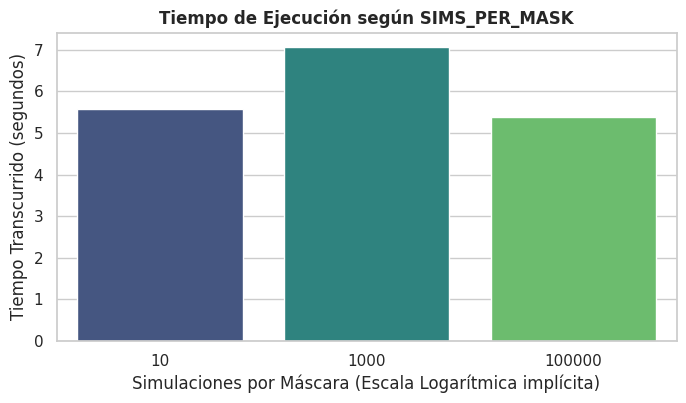

In [ ]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Definimos los diferentes escenarios de SIMS_PER_MASK requeridos
escenarios_sims = [10, 1000, 100000]
resultados_comparativa = []

for sims in escenarios_sims:
    print(f"\n⏳ Ejecutando simulación para SIMS_PER_MASK = {sims}...")
    global SIMS_PER_MASK
    SIMS_PER_MASK = sims

    start_time = time.time()
    estado_simulado = play_game(verbose_each_turn=False)
    elapsed_time = time.time() - start_time

    p1, p2 = estado_simulado.players
    resultados_comparativa.append({
        "Sims por Máscara": sims,
        "Tiempo (s)": round(elapsed_time, 4),
        "Puntos Jugador 1": p1.total,
        "Puntos Jugador 2": p2.total,
        "Ganador": p1.name if p1.total > p2.total else (p2.name if p2.total > p1.total else "Empate"),
        "Total Lanzamientos": estado_simulado.stats.total_rolls
    })

# Presentar resultados en una tabla
df_comparativo = pd.DataFrame(resultados_comparativa)
print("\n=== TABLA COMPARATIVA DE ESCENARIOS ===")
print(df_comparativo.to_string(index=False))

# Graficar el tiempo de ejecución según el número de simulaciones
plt.figure(figsize=(8, 4))
sns.barplot(x="Sims por Máscara", y="Tiempo (s)", data=df_comparativo, palette="viridis")
plt.title("Tiempo de Ejecución según SIMS_PER_MASK", fontsize=12, fontweight="bold")
plt.ylabel("Tiempo Transcurrido (segundos)")
plt.xlabel("Simulaciones por Máscara (Escala Logarítmica implícita)")
plt.show()

✅ Diagrama de flujo generado y guardado como 'diagrama_flujo_yahtzee.png'

⏳ Iniciando experimento de convergencia...
   Iteraciones:     10 | EV Estimado: 18.9000 | Tiempo: 0.0003s
   Iteraciones:    100 | EV Estimado: 18.6600 | Tiempo: 0.0019s
   Iteraciones:    500 | EV Estimado: 18.0940 | Tiempo: 0.0093s
   Iteraciones:   1000 | EV Estimado: 18.5190 | Tiempo: 0.0175s
   Iteraciones:   5000 | EV Estimado: 18.2880 | Tiempo: 0.0896s
   Iteraciones:  10000 | EV Estimado: 18.3277 | Tiempo: 0.1808s
   Iteraciones:  50000 | EV Estimado: 18.3077 | Tiempo: 1.2299s
   Iteraciones: 100000 | EV Estimado: 18.3098 | Tiempo: 3.0178s


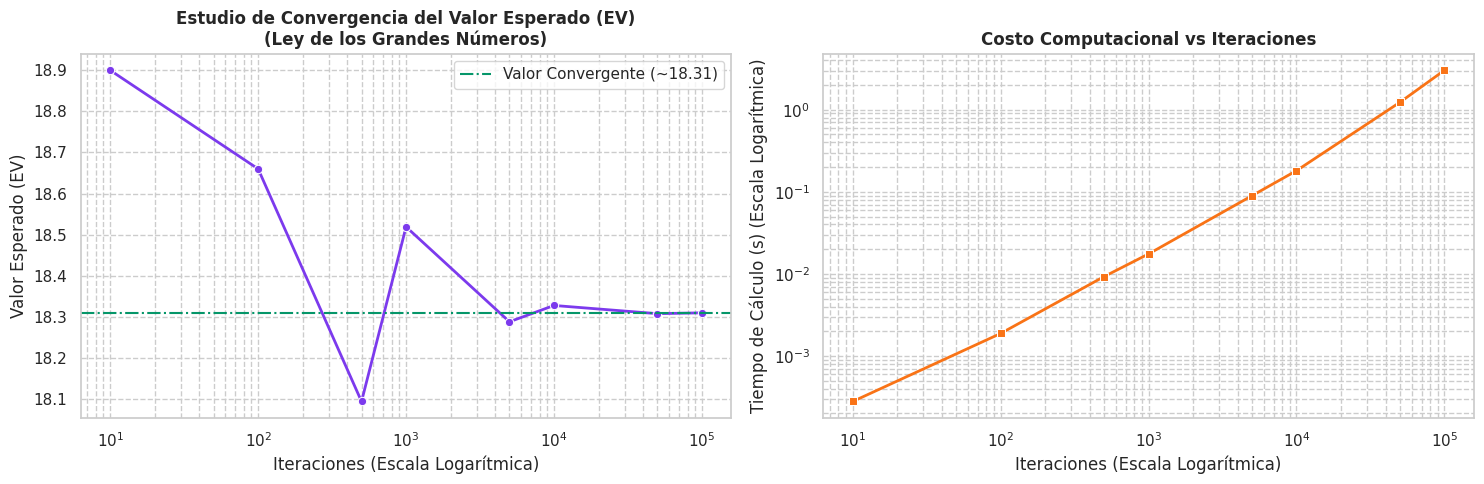

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from graphviz import Digraph

# =========================================================
# 1. GENERACIÓN DEL DIAGRAMA DE FLUJO (Graphviz)
# =========================================================
def generar_diagrama_flujo():
    dot = Digraph(comment='Yahtzee Montecarlo - Flujo de decisión', format='png')
    dot.attr(rankdir='TB', bgcolor='#0F172A', pad='0.4', nodesep='0.5', ranksep='0.55',
             dpi='200', fontname='Helvetica', splines='spline')
    dot.attr('node', shape='box', style='filled,rounded,bold', color='#38BDF8',
             fillcolor='#1E293B', fontcolor='#F1F5F9', fontname='Helvetica', fontsize='11', penwidth='1.6')
    dot.attr('edge', color='#94A3B8', fontcolor='#FDE68A', fontname='Helvetica', fontsize='10', penwidth='1.4')

    dot.node('inicio', '🎲 Inicio de turno\nSemilla aleatoria única', shape='ellipse', color='#34D399', fillcolor='#064E3B')
    dot.node('rng', 'Tirar dados no bloqueados\nfloor(random() × 6) + 1', color='#F472B6', fillcolor='#500724')
    dot.node('eval_tiros', '¿rolls_left > 0?', shape='diamond', color='#FBBF24', fillcolor='#422006')
    dot.node('eval_mascaras', 'Generar las 32\nmáscaras de bloqueo', color='#A78BFA', fillcolor='#2E1065')
    dot.node('montecarlo', 'Montecarlo por máscara:\nN simulaciones → EV', color='#38BDF8', fillcolor='#0C4A6E')
    dot.node('mejor_mascara', 'Elegir máscara\ncon máximo EV', color='#38BDF8', fillcolor='#0C4A6E')
    dot.node('plantarse', '¿Mantener\ntodos los dados?', shape='diamond', color='#FBBF24', fillcolor='#422006')
    dot.node('anotar', 'Anotar en la mejor\ncategoría libre', color='#FB923C', fillcolor='#431407')
    dot.node('fin', 'Fin del turno', shape='ellipse', color='#F87171', fillcolor='#450A0A')

    dot.edge('inicio', 'rng')
    dot.edge('rng', 'eval_tiros')
    dot.edge('eval_tiros', 'eval_mascaras', label='Sí')
    dot.edge('eval_tiros', 'anotar', label='No')
    dot.edge('eval_mascaras', 'montecarlo')
    dot.edge('montecarlo', 'mejor_mascara')
    dot.edge('mejor_mascara', 'plantarse')
    dot.edge('plantarse', 'anotar', label='Sí (plantarse)')
    dot.edge('plantarse', 'rng', label='No (bloquear y relanzar)')
    dot.edge('anotar', 'fin')

    return dot

# Guardar y renderizar el diagrama de flujo
dot = generar_diagrama_flujo()
dot.render('diagrama_flujo_yahtzee', cleanup=True)
print("✅ Diagrama de flujo generado y guardado como 'diagrama_flujo_yahtzee.png'")

# =========================================================
# 2. ESTUDIO DE CONVERGENCIA (Ley de los Grandes Números)
# =========================================================
def reporte_convergencia_lln():
    # Escenario de dados de prueba: Buscamos Full House o Trío con dados iniciales [3, 3, 5, 2, 6]
    dados_iniciales = [3, 3, 5, 2, 6]
    categorias_disponibles = ["threes", "fullHouse", "threeOfKind", "chance"]
    # Queremos evaluar mantener los dos 3s (Máscara: [True, True, False, False, False])
    mascara_keep = [True, True, False, False, False]

    valores_iteraciones = [10, 100, 500, 1000, 5000, 10000, 50000, 100000]
    ev_estimados = []
    tiempos = []

    print("\n⏳ Iniciando experimento de convergencia...")
    for sims in valores_iteraciones:
        t_init = time.time()
        ev = simulate_expected_value_after_keeps(
            current_values=dados_iniciales,
            keep_mask=mascara_keep,
            rolls_remaining=2,
            available_categories=categorias_disponibles,
            sims=sims
        )
        t_elapsed = time.time() - t_init
        ev_estimados.append(ev)
        tiempos.append(t_elapsed)
        print(f"   Iteraciones: {sims:6d} | EV Estimado: {ev:.4f} | Tiempo: {t_elapsed:.4f}s")

    # Crear DataFrame de resultados
    df_conv = pd.DataFrame({
        "Iteraciones": valores_iteraciones,
        "EV Estimado": ev_estimados,
        "Tiempo de Cálculo (s)": tiempos
    })

    # Graficar la Convergencia
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Subplot 1: Convergencia de EV (Ley de los Grandes Números)
    sns.lineplot(x="Iteraciones", y="EV Estimado", data=df_conv, ax=ax1, marker="o", color="#7C3AED", linewidth=2)
    ax1.set_xscale('log')
    # Línea de referencia del valor asintótico/verdadero
    valor_teorico = ev_estimados[-1]
    ax1.axhline(y=valor_teorico, color='#059669', linestyle='-.', label=f'Valor Convergente (~{valor_teorico:.2f})')
    ax1.set_title("Estudio de Convergencia del Valor Esperado (EV)\n(Ley de los Grandes Números)", fontsize=12, fontweight='bold')
    ax1.set_xlabel("Iteraciones (Escala Logarítmica)")
    ax1.set_ylabel("Valor Esperado (EV)")
    ax1.legend()
    ax1.grid(True, which="both", ls="--")

    # Subplot 2: Costo Computacional (Tiempo vs Iteraciones)
    sns.lineplot(x="Iteraciones", y="Tiempo de Cálculo (s)", data=df_conv, ax=ax2, marker="s", color="#F97316", linewidth=2)
    ax2.set_xscale('log')
    ax2.set_yscale('log')
    ax2.set_title("Costo Computacional vs Iteraciones", fontsize=12, fontweight='bold')
    ax2.set_xlabel("Iteraciones (Escala Logarítmica)")
    ax2.set_ylabel("Tiempo de Cálculo (s) (Escala Logarítmica)")
    ax2.grid(True, which="both", ls="--")

    plt.tight_layout()
    plt.show()

# Ejecutar el análisis
reporte_convergencia_lln()


🎲 Semilla de esta ejecución: 1650592502
🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...
✅ Simulación completada.

 📊 ANÁLISIS DE LA PARTIDA Y TOMA DE DECISIONES

🏆 Resultado de la Simulación: ¡El ganador es Jugador 1!

    Categoría  Jugador 1  Jugador 2
         ones          0          0
         twos          4          6
       threes          3          3
        fours          8          4
        fives         10          5
        sixes          6         12
  threeOfKind         14         26
   fourOfKind          0          0
    fullHouse         25         25
smallStraight         30          0
largeStraight          0          0
      yahtzee          0          0
       chance         18         18
------------------------------
PUNTUACIÓN TOTAL | Jugador 1: 118 | Jugador 2: 99


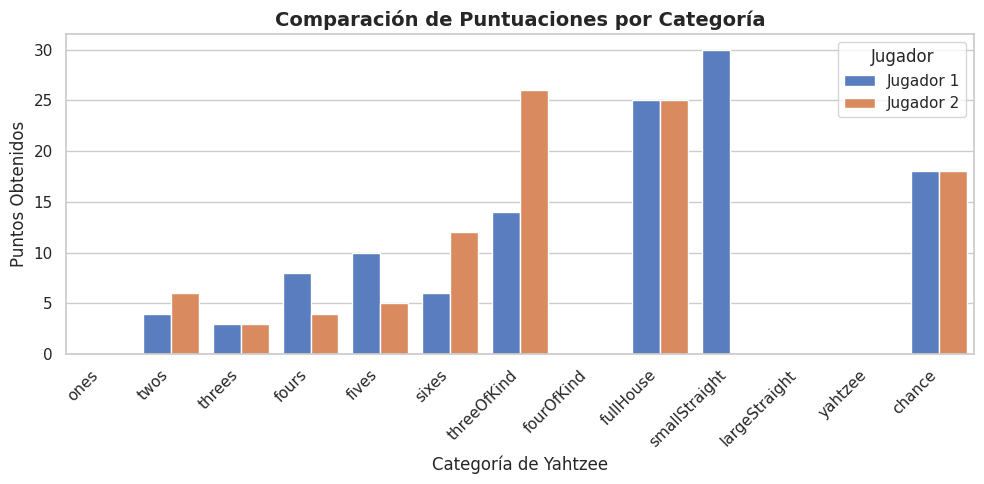


 🎲 ANÁLISIS DEL MOTOR DE DADOS (Validación de Montecarlo)

En una simulación de Montecarlo, es vital comprobar si nuestro generador aleatorio es justo.
Teóricamente, cada cara de un dado perfecto tiene una probabilidad de: 1/6 = 16.67%
Veamos cómo se comportaron nuestros dados tras 370 lanzamientos individuales:

 Cara 1: Salió 57 veces -> 15.41% (Diferencia vs Teoría: 1.26%)
 Cara 2: Salió 63 veces -> 17.03% (Diferencia vs Teoría: 0.36%)
 Cara 3: Salió 54 veces -> 14.59% (Diferencia vs Teoría: 2.08%)
 Cara 4: Salió 53 veces -> 14.32% (Diferencia vs Teoría: 2.35%)
 Cara 5: Salió 67 veces -> 18.11% (Diferencia vs Teoría: 1.44%)
 Cara 6: Salió 76 veces -> 20.54% (Diferencia vs Teoría: 3.87%)


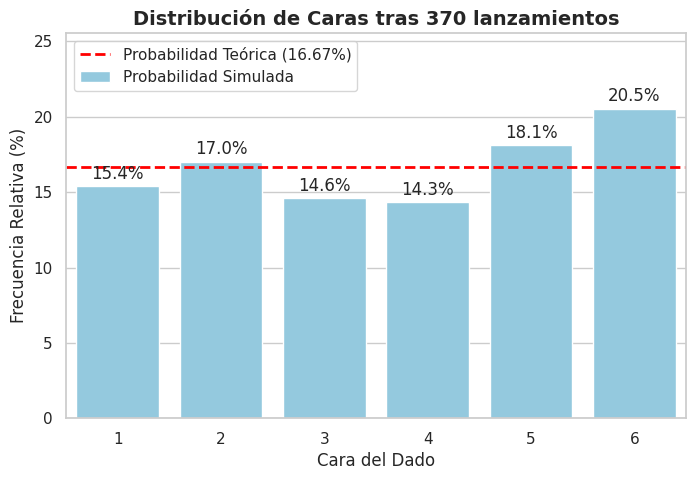


💡 REFLEXIÓN DIDÁCTICA:
Observa el gráfico de distribución. La línea punteada roja representa la probabilidad matemática ideal.
Las barras azules son el resultado de la simulación. Gracias a la 'Ley de los Grandes Números', notarás
que a medida que la simulación realiza más lanzamientos, las barras azules se acercarán cada vez más a la línea roja.


In [ ]:
import math
import random
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from typing import List, Dict, Optional, Tuple

# Importamos librerías para visualización de datos (El toque didáctico)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# ===============================
# Parámetros Montecarlo
# ===============================
SIMS_PER_MASK = 300  # nº de simulaciones por máscara de bloqueo (32 máx). Ajusta si quieres más/menos precisión.
SEED = None          # None = semilla distinta en CADA ejecución (cada compañero obtiene valores diferentes)
                     # Para reproducir una corrida concreta, pon aquí el número que se imprime abajo.

if SEED is None:
    # Semilla tomada de la entropía del sistema operativo: nunca se repite entre ejecuciones/personas
    SEED = random.SystemRandom().randrange(2**32)
random.seed(SEED)
print(f"🎲 Semilla de esta ejecución: {SEED}")

# ===============================
# Utilidades de dados
# ===============================
def roll_single_die() -> int:
    """Equivalente en Python de Math.floor(Math.random() * 6) + 1 (JavaScript).
    random.random() -> pseudoaleatorio uniforme en [0,1); se escala a [0,6) y se
    toma la parte entera (floor) para obtener un entero en [1,6]."""
    return math.floor(random.random() * 6) + 1

def roll_dice(values: List[int], locked: List[bool]) -> None:
    """Lanza dados no bloqueados, actualizando 'values' in place."""
    for i, is_locked in enumerate(locked):
        if not is_locked:
            values[i] = roll_single_die()

def has_sequence(values: List[int], needed_len: int) -> bool:
    """¿Existe una secuencia consecutiva de longitud 'needed_len'? (ignora duplicados)."""
    uniq = sorted(set(values))
    if not uniq:
        return False
    longest = curr = 1
    for i in range(1, len(uniq)):
        if uniq[i] == uniq[i-1] + 1:
            curr += 1
            longest = max(longest, curr)
        else:
            curr = 1
    return longest >= needed_len

# ===============================
# Puntuación
# ===============================
CATEGORIES_ORDER = [
    "ones","twos","threes","fours","fives","sixes",
    "threeOfKind","fourOfKind","fullHouse","smallStraight",
    "largeStraight","yahtzee","chance"
]

def score_hand(category: str, dice: List[int]) -> int:
    counts = Counter(dice)
    freqs = list(counts.values())
    total = sum(dice)
    if category in ["ones","twos","threes","fours","fives","sixes"]:
        num = {"ones":1, "twos":2, "threes":3, "fours":4, "fives":5, "sixes":6}[category]
        return counts.get(num, 0) * num
    if category == "threeOfKind":
        return total if any(f >= 3 for f in freqs) else 0
    if category == "fourOfKind":
        return total if any(f >= 4 for f in freqs) else 0
    if category == "fullHouse":
        return 25 if (2 in freqs and 3 in freqs) else 0
    if category == "smallStraight":
        return 30 if has_sequence(dice, 4) else 0
    if category == "largeStraight":
        return 40 if has_sequence(dice, 5) else 0
    if category == "yahtzee":
        return 50 if 5 in freqs else 0
    if category == "chance":
        return total
    return 0

def best_category_score(dice: List[int], available: List[str]) -> Tuple[str, int]:
    """Devuelve (mejor_categoria, puntuación) para los dados dados."""
    best_cat, best = None, -1
    for cat in available:
        sc = score_hand(cat, dice)
        if sc > best:
            best = sc
            best_cat = cat
    return best_cat, best

# ===============================
# Estructuras de juego
# ===============================
@dataclass
class PlayerState:
    name: str
    scores: Dict[str, Optional[int]] = field(default_factory=lambda: {c: None for c in CATEGORIES_ORDER})
    total: int = 0

    def available_categories(self) -> List[str]:
        return [c for c,v in self.scores.items() if v is None]

    def set_score(self, category: str, points: int) -> None:
        self.scores[category] = points
        self.total = sum(v for v in self.scores.values() if v is not None)

@dataclass
class GameStats:
    total_rolls: int = 0
    face_hist: Counter = field(default_factory=Counter)

    def update_from_roll(self, values: List[int]) -> None:
        self.total_rolls += sum(1 for _ in values)  # 5 por tirada
        self.face_hist.update(values)

@dataclass
class GameState:
    players: List[PlayerState]
    current_player_idx: int = 0
    turn_in_round: int = 0  # 0..12 (13 turnos)
    dice_values: List[int] = field(default_factory=lambda: [0]*5)
    locked: List[bool] = field(default_factory=lambda: [False]*5)
    rolls_left: int = 3
    stats: GameStats = field(default_factory=GameStats)

    def reset_turn(self):
        self.dice_values = [0]*5
        self.locked = [False]*5
        self.rolls_left = 3

    @property
    def current_player(self) -> PlayerState:
        return self.players[self.current_player_idx]

    def advance_player(self):
        self.current_player_idx = (self.current_player_idx + 1) % len(self.players)
        if self.current_player_idx == 0:
            self.turn_in_round += 1

# ===============================
# Montecarlo para decidir bloqueos
# ===============================
def all_keep_masks() -> List[List[bool]]:
    masks = []
    for m in range(32):
        mask = [(m >> i) & 1 == 1 for i in range(5)]
        masks.append(mask)
    return masks

def simulate_expected_value_after_keeps(
    current_values: List[int], keep_mask: List[bool], rolls_remaining: int,
    available_categories: List[str], sims: int
) -> float:
    if rolls_remaining <= 0:
        _, sc = best_category_score(current_values, available_categories)
        return float(sc)

    kept = [v if keep_mask[i] else None for i, v in enumerate(current_values)]
    unlocked_idx = [i for i,b in enumerate(keep_mask) if not b]

    total_score = 0.0
    for _ in range(sims):
        vals = kept[:]
        temp = current_values[:]
        for _r in range(rolls_remaining):
            for i in unlocked_idx:
                temp[i] = roll_single_die()
        for i in range(5):
            vals[i] = vals[i] if vals[i] is not None else temp[i]

        _, sc = best_category_score(vals, available_categories)
        total_score += sc

    return total_score / sims if sims > 0 else 0.0

def choose_keep_mask_montecarlo(
    current_values: List[int], rolls_remaining: int,
    available_categories: List[str], sims_per_mask: int = SIMS_PER_MASK
) -> List[bool]:
    best_mask = None
    best_ev = -1.0
    for mask in all_keep_masks():
        ev = simulate_expected_value_after_keeps(
            current_values, mask, rolls_remaining - 1, available_categories, sims_per_mask
        )
        if ev > best_ev:
            best_ev = ev
            best_mask = mask
    return best_mask

# ===============================
# Flujo del juego
# ===============================
def play_one_turn(state: GameState, verbose: bool = False): # Apagamos el verbose por defecto para no ensuciar la salida final
    player = state.current_player
    state.reset_turn()

    roll_dice(state.dice_values, state.locked)
    state.stats.update_from_roll(state.dice_values)
    state.rolls_left -= 1
    if verbose: print(f"\n{player.name} — Tirada 1:", state.dice_values)

    while state.rolls_left > 0:
        keep_mask = choose_keep_mask_montecarlo(
            state.dice_values, state.rolls_left, player.available_categories()
        )
        if all(keep_mask):
            if verbose: print(f"{player.name} decide plantarse con:", state.dice_values)
            break

        state.locked = keep_mask[:]
        roll_dice(state.dice_values, state.locked)
        state.stats.update_from_roll(state.dice_values)
        state.rolls_left -= 1
        if verbose: print(f"{player.name} — Tirada {3 - state.rolls_left}:", state.dice_values, "| keep:", keep_mask)

    cat, sc = best_category_score(state.dice_values, player.available_categories())
    player.set_score(cat, sc)
    if verbose: print(f"→ {player.name} elige '{cat}' y anota {sc} pts. Total = {player.total}")

def play_game(verbose_each_turn: bool = False) -> GameState:
    players = [PlayerState("Jugador 1"), PlayerState("Jugador 2")]
    state = GameState(players=players)
    total_rounds = 13

    print("🎲 Iniciando simulación de Montecarlo (Motor de IA tomando decisiones)...")
    for r in range(total_rounds):
        for _p in range(len(players)):
            play_one_turn(state, verbose=verbose_each_turn)
            state.advance_player()  # <--- ¡Esta es la línea que faltaba!
    print("✅ Simulación completada.\n")
    return state
# ===============================
# Ejecutar simulación completa
# ===============================
# Ejecutamos en silencio para priorizar el análisis final
estado_final = play_game(verbose_each_turn=False)


# =========================================================
# REFACTORIZACIÓN DIDÁCTICA: ANÁLISIS Y VISUALIZACIÓN
# =========================================================
def analisis_didactico_resultados(state: GameState):
    """Presenta los resultados de la simulación de forma visual y pedagógica."""

    # Configuración visual de Seaborn
    sns.set_theme(style="whitegrid")

    # --- 1. RESUMEN DEL PARTIDO (TABLA VISUAL) ---
    print("="*50)
    print(" 📊 ANÁLISIS DE LA PARTIDA Y TOMA DE DECISIONES")
    print("="*50)

    # Determinamos al ganador
    p1, p2 = state.players
    if p1.total > p2.total:
        ganador = p1.name
    elif p2.total > p1.total:
        ganador = p2.name
    else:
        ganador = "Empate"

    print(f"\n🏆 Resultado de la Simulación: ¡El ganador es {ganador}!\n")

    # Construimos un DataFrame de Pandas para que los estudiantes vean una tabla estructurada
    df_scores = pd.DataFrame({
        "Categoría": CATEGORIES_ORDER,
        p1.name: [p1.scores[c] if p1.scores[c] is not None else 0 for c in CATEGORIES_ORDER],
        p2.name: [p2.scores[c] if p2.scores[c] is not None else 0 for c in CATEGORIES_ORDER]
    })

    # Mostramos la tabla formateada
    print(df_scores.to_string(index=False))
    print("-" * 30)
    print(f"PUNTUACIÓN TOTAL | {p1.name}: {p1.total} | {p2.name}: {p2.total}")

    # --- GRÁFICO 1: COMPARACIÓN DE PUNTUACIONES ---
    plt.figure(figsize=(10, 5))
    ax = sns.barplot(x="Categoría", y="Valor", hue="Jugador",
                     data=pd.melt(df_scores, id_vars="Categoría", var_name="Jugador", value_name="Valor"),
                     palette="muted")
    plt.title("Comparación de Puntuaciones por Categoría", fontsize=14, fontweight="bold")
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Puntos Obtenidos")
    plt.xlabel("Categoría de Yahtzee")
    plt.tight_layout()
    plt.show()

    # --- 2. ANÁLISIS DE PROBABILIDAD Y LA LEY DE LOS GRANDES NÚMEROS ---
    print("\n" + "="*50)
    print(" 🎲 ANÁLISIS DEL MOTOR DE DADOS (Validación de Montecarlo)")
    print("="*50)
    print("\nEn una simulación de Montecarlo, es vital comprobar si nuestro generador aleatorio es justo.")
    print(f"Teóricamente, cada cara de un dado perfecto tiene una probabilidad de: 1/6 = 16.67%")
    print(f"Veamos cómo se comportaron nuestros dados tras {state.stats.total_rolls} lanzamientos individuales:\n")



    total_faces = sum(state.stats.face_hist.values())
    caras = list(range(1, 7))
    frecuencias = [state.stats.face_hist.get(face, 0) for face in caras]
    probabilidades_empiricas = [(frec / total_faces) * 100 if total_faces else 0 for frec in frecuencias]

    # Imprimimos los resultados teóricos vs simulados
    for face, frec, prob in zip(caras, frecuencias, probabilidades_empiricas):
        error_marginal = abs(prob - 16.67)
        print(f" Cara {face}: Salió {frec} veces -> {prob:.2f}% (Diferencia vs Teoría: {error_marginal:.2f}%)")

    # --- GRÁFICO 2: DISTRIBUCIÓN DE PROBABILIDAD ---
    plt.figure(figsize=(8, 5))

    # Graficamos los datos empíricos
    bar_plot = sns.barplot(x=caras, y=probabilidades_empiricas, color="skyblue", label="Probabilidad Simulada")

    # Agregamos la línea teórica del 16.67%
    plt.axhline(y=16.67, color='red', linestyle='--', linewidth=2, label='Probabilidad Teórica (16.67%)')

    plt.title(f"Distribución de Caras tras {state.stats.total_rolls} lanzamientos", fontsize=14, fontweight="bold")
    plt.xlabel("Cara del Dado")
    plt.ylabel("Frecuencia Relativa (%)")
    plt.ylim(0, max(probabilidades_empiricas) + 5) # Damos espacio arriba
    plt.legend()

    # Añadir los porcentajes encima de las barras para máxima claridad
    for p in bar_plot.patches:
        bar_plot.annotate(format(p.get_height(), '.1f') + '%',
                          (p.get_x() + p.get_width() / 2., p.get_height()),
                          ha = 'center', va = 'center',
                          xytext = (0, 9),
                          textcoords = 'offset points')

    plt.show()

    print("\n💡 REFLEXIÓN DIDÁCTICA:")
    print("Observa el gráfico de distribución. La línea punteada roja representa la probabilidad matemática ideal.")
    print("Las barras azules son el resultado de la simulación. Gracias a la 'Ley de los Grandes Números', notarás")
    print("que a medida que la simulación realiza más lanzamientos, las barras azules se acercarán cada vez más a la línea roja.")

# Llamamos a la nueva función de presentación
analisis_didactico_resultados(estado_final)